# Logistic Regression — Insurance Fraud Detection
**Project 2 | Insurance domain | Educational demonstration**

This notebook downloads a public insurance-claims dataset, validates its schema, performs exploratory analysis, trains a reproducible scikit-learn pipeline, evaluates the model, creates graphs, and exports artifacts for the Streamlit app.

> **Important:** This dataset contains historical labels and potentially post-incident or post-investigation fields. This project is for education only. Before any real deployment, perform feature-timing/leakage review, privacy/legal review, and independent validation. Do not use this model to deny claims, set premiums, or make decisions about individuals.

## 1. Reproducibility and source/license

Dataset record: Mendeley Data, *insurance_claims*, version 2, DOI `10.17632/992mh7dk9y.2`. The record states CC BY 4.0 and links to the CSV repository below. Review the record and attribution terms before redistributing the data.

- Dataset record: https://data.mendeley.com/datasets/992mh7dk9y/2
- Linked CSV: https://github.com/mwitiderrick/insurancedata/blob/master/insurance_claims.csv
- Raw CSV URL used below: https://raw.githubusercontent.com/mwitiderrick/insurancedata/master/insurance_claims.csv

We save the data-source URL and library versions with the model artifacts. GitHub availability alone is not a license; check the dataset record before redistribution.

In [1]:
# 1.1 Imports and environment versions
import sys, json, warnings, hashlib
from pathlib import Path
from urllib.request import urlopen
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn, scipy, joblib

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    roc_auc_score, roc_curve, precision_recall_curve, average_precision_score,
    accuracy_score, precision_score, recall_score, f1_score
)

RANDOM_STATE = 42
DATA_URL = "https://raw.githubusercontent.com/mwitiderrick/insurancedata/master/insurance_claims.csv"
DATASET_RECORD = "https://data.mendeley.com/datasets/992mh7dk9y/2"
TARGET = "fraud_reported"
ARTIFACT_DIR = Path("artifacts")
ARTIFACT_DIR.mkdir(exist_ok=True)

print("Python:", sys.version)
print("scikit-learn:", sklearn.__version__)
print("NumPy:", np.__version__)
print("SciPy:", scipy.__version__)
print("joblib:", joblib.__version__)

Python: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
scikit-learn: 1.6.1
NumPy: 2.1.3
SciPy: 1.16.3
joblib: 1.6.0


## 2. Load data and validate expected target

In [2]:
# Download CSV. If the URL changes, download from the source record and upload the file.
data_path = Path("insurance_claims.csv")
try:
    with urlopen(DATA_URL, timeout=30) as response:
        raw_bytes = response.read()
    data_path.write_bytes(raw_bytes)
except Exception as exc:
    raise RuntimeError(
        "Dataset download failed. Download insurance_claims.csv from the linked source "
        "record and place it next to this notebook, then rerun this cell."
    ) from exc

df = pd.read_csv(data_path)
print("Shape:", df.shape)
display(df.head())
print("Columns:", df.columns.tolist())

if TARGET not in df.columns:
    raise ValueError(f"Expected target column {TARGET!r} not found. Inspect source schema.")

print("\nTarget values:")
display(df[TARGET].value_counts(dropna=False).to_frame("count"))

Shape: (1000, 39)


,months_as_customer,age,policy_number,policy_bind_date,policy_state,policy_csl,policy_deductable,policy_annual_premium,umbrella_limit,insured_zip,...,witnesses,police_report_available,total_claim_amount,injury_claim,property_claim,vehicle_claim,auto_make,auto_model,auto_year,fraud_reported
0,328,48,521585,2014-10-17,OH,250/500,1000,1406.91,0,466132,...,2,YES,71610,6510,13020,52080,Saab,92x,2004,Y
1,228,42,342868,2006-06-27,IN,250/500,2000,1197.22,5000000,468176,...,0,?,5070,780,780,3510,Mercedes,E400,2007,Y
2,134,29,687698,2000-09-06,OH,100/300,2000,1413.14,5000000,430632,...,3,NO,34650,7700,3850,23100,Dodge,RAM,2007,N
3,256,41,227811,1990-05-25,IL,250/500,2000,1415.74,6000000,608117,...,2,NO,63400,6340,6340,50720,Chevrolet,Tahoe,2014,Y
4,228,44,367455,2014-06-06,IL,500/1000,1000,1583.91,6000000,610706,...,1,NO,6500,1300,650,4550,Accura,RSX,2009,N


Columns: ['months_as_customer', 'age', 'policy_number', 'policy_bind_date', 'policy_state', 'policy_csl', 'policy_deductable', 'policy_annual_premium', 'umbrella_limit', 'insured_zip', 'insured_sex', 'insured_education_level', 'insured_occupation', 'insured_hobbies', 'insured_relationship', 'capital-gains', 'capital-loss', 'incident_date', 'incident_type', 'collision_type', 'incident_severity', 'authorities_contacted', 'incident_state', 'incident_city', 'incident_location', 'incident_hour_of_the_day', 'number_of_vehicles_involved', 'property_damage', 'bodily_injuries', 'witnesses', 'police_report_available', 'total_claim_amount', 'injury_claim', 'property_claim', 'vehicle_claim', 'auto_make', 'auto_model', 'auto_year', 'fraud_reported']

Target values:


,count
fraud_reported,
N,753
Y,247


## 3. Data quality and exploratory analysis

Duplicate rows: 0


,missing_count
authorities_contacted,91


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
months_as_customer,1000.0,NaN,NaN,NaN,203.954,115.113174,0.0,115.75,199.5,276.25,479.0
age,1000.0,NaN,NaN,NaN,38.948,9.140287,19.0,32.0,38.0,44.0,64.0
policy_number,1000.0,NaN,NaN,NaN,546238.648,257063.005276,100804.0,335980.25,533135.0,759099.75,999435.0
policy_bind_date,1000,951,1992-08-05,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
policy_state,1000,3,OH,352,NaN,NaN,NaN,NaN,NaN,NaN,NaN
policy_csl,1000,3,250/500,351,NaN,NaN,NaN,NaN,NaN,NaN,NaN
policy_deductable,1000.0,NaN,NaN,NaN,1136.0,611.864673,500.0,500.0,1000.0,2000.0,2000.0
policy_annual_premium,1000.0,NaN,NaN,NaN,1256.40615,244.167395,433.33,1089.6075,1257.2,1415.695,2047.59
umbrella_limit,1000.0,NaN,NaN,NaN,1101000.0,2297406.598118,-1000000.0,0.0,0.0,0.0,10000000.0
insured_zip,1000.0,NaN,NaN,NaN,501214.488,71701.610941,430104.0,448404.5,466445.5,603251.0,620962.0


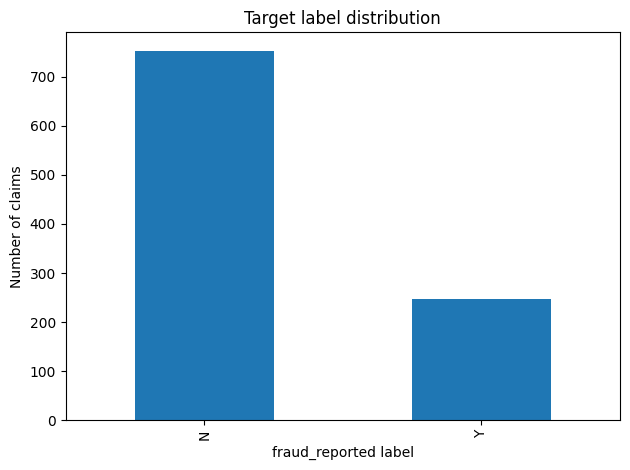

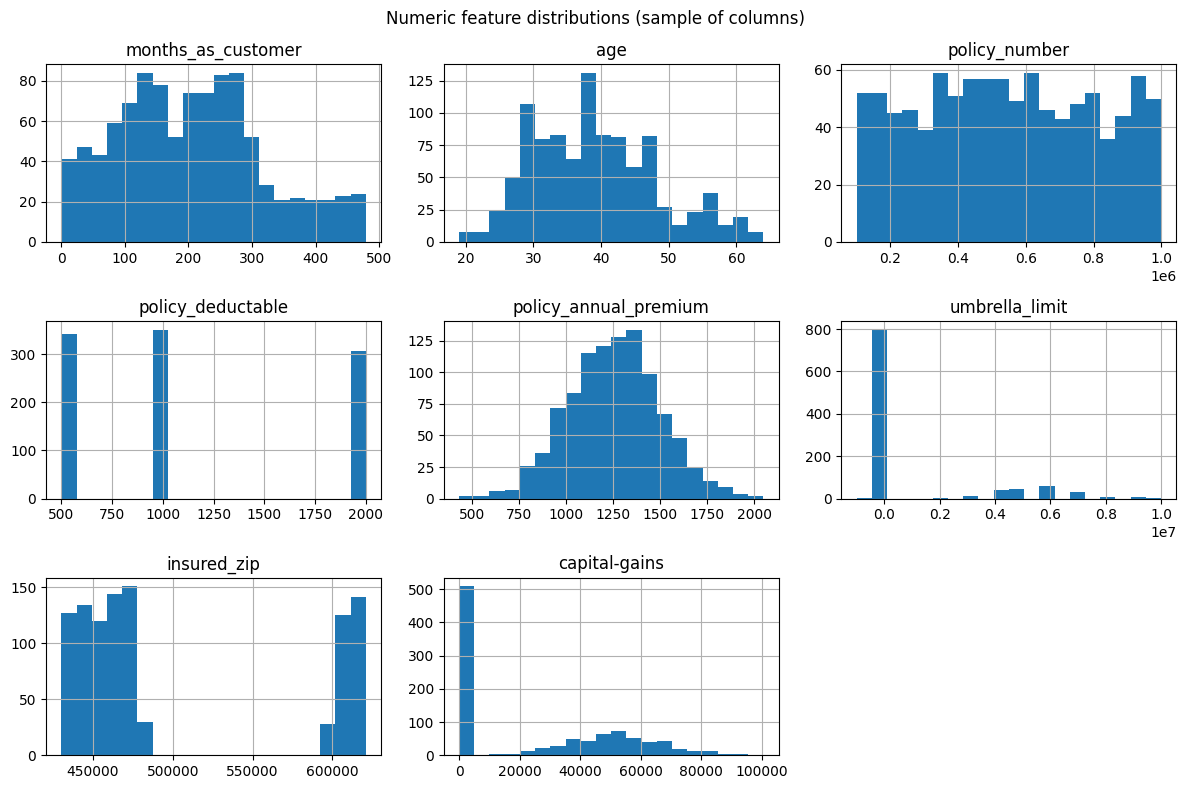

In [3]:
# Remove completely empty rows; report duplicates and missing values before any decisions.
df = df.dropna(how="all").copy()
print("Duplicate rows:", int(df.duplicated().sum()))
missing = df.isna().sum().sort_values(ascending=False)
display(missing[missing > 0].to_frame("missing_count"))
display(df.describe(include="all").T.head(30))

# Target distribution plot
target_counts = df[TARGET].astype(str).value_counts()
ax = target_counts.plot(kind="bar", title="Target label distribution")
ax.set_xlabel("fraud_reported label")
ax.set_ylabel("Number of claims")
plt.tight_layout()
plt.show()

# Numeric feature histograms (first few only, to keep notebook readable)
numeric_preview = df.select_dtypes(include=np.number).columns.tolist()[:8]
if numeric_preview:
    df[numeric_preview].hist(figsize=(12, 8), bins=20)
    plt.suptitle("Numeric feature distributions (sample of columns)")
    plt.tight_layout()
    plt.show()

## 4. Target preparation and leakage review

The target in the source is commonly represented as `Y`/`N`; this cell validates observed labels instead of silently guessing. We drop the target and obvious identifier fields. This is still an educational baseline, not a production-ready fraud model: inspect all feature definitions and determine whether they were known at the intended prediction time. Fields generated during investigation or after claim adjudication can leak the answer and must be removed before any operational use.

In [4]:
# Normalize target labels explicitly and fail if unexpected values appear.
target_values = set(df[TARGET].dropna().astype(str).str.strip().str.upper().unique())
print("Observed target labels:", target_values)
mapping = {"Y": 1, "N": 0, "1": 1, "0": 0, "TRUE": 1, "FALSE": 0}
if not target_values.issubset(mapping):
    raise ValueError(f"Unexpected target labels {target_values}; update mapping after source review.")

df = df.loc[df[TARGET].notna()].copy()
y = df[TARGET].astype(str).str.strip().str.upper().map(mapping).astype(int)

# Exclude target and obvious identifier fields; extend this list after a documented leakage review.
identifier_candidates = [
    col for col in df.columns
    if col.lower() in {"policy_number", "insured_zip", "incident_location", "incident_date", "policy_bind_date"}
]
X = df.drop(columns=[TARGET] + identifier_candidates, errors="ignore").copy()

# Remove constant columns: they contain no useful variation for this model.
constant_columns = [col for col in X.columns if X[col].nunique(dropna=False) <= 1]
X = X.drop(columns=constant_columns)

print("Excluded identifier candidates:", identifier_candidates)
print("Excluded constant columns:", constant_columns)
print("Features:", X.shape[1])
print("Target rate:", round(float(y.mean()), 4))
display(pd.DataFrame({"dtype": X.dtypes.astype(str), "missing": X.isna().sum(), "unique": X.nunique(dropna=False)}))

Observed target labels: {'N', 'Y'}
Excluded identifier candidates: ['policy_number', 'policy_bind_date', 'insured_zip', 'incident_date', 'incident_location']
Excluded constant columns: []
Features: 33
Target rate: 0.247


,dtype,missing,unique
months_as_customer,int64,0,391
age,int64,0,46
policy_state,object,0,3
policy_csl,object,0,3
policy_deductable,int64,0,3
policy_annual_premium,float64,0,991
umbrella_limit,int64,0,11
insured_sex,object,0,2
insured_education_level,object,0,7
insured_occupation,object,0,14


## 5. Train/test split and preprocessing pipeline

The split is stratified so the class proportions are approximately preserved. Numeric columns are median-imputed and scaled; categorical columns are most-frequent-imputed and one-hot encoded. All preprocessing is fit only on the training partition through a single pipeline to reduce leakage.

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

numeric_features = X_train.select_dtypes(include=np.number).columns.tolist()
categorical_features = [c for c in X_train.columns if c not in numeric_features]

numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])
preprocessor = ColumnTransformer(transformers=[
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE
    ))
])
pipeline.fit(X_train, y_train)
print("Pipeline training complete.")

Pipeline training complete.


## 6. Evaluate and visualize

,test_value
accuracy,0.830000
precision,0.641509
recall,0.693878
f1,0.666667
roc_auc,0.824976
average_precision,0.526417


                    precision    recall  f1-score   support

Not reported fraud       0.90      0.87      0.89       151
    Reported fraud       0.64      0.69      0.67        49

          accuracy                           0.83       200
         macro avg       0.77      0.78      0.78       200
      weighted avg       0.84      0.83      0.83       200



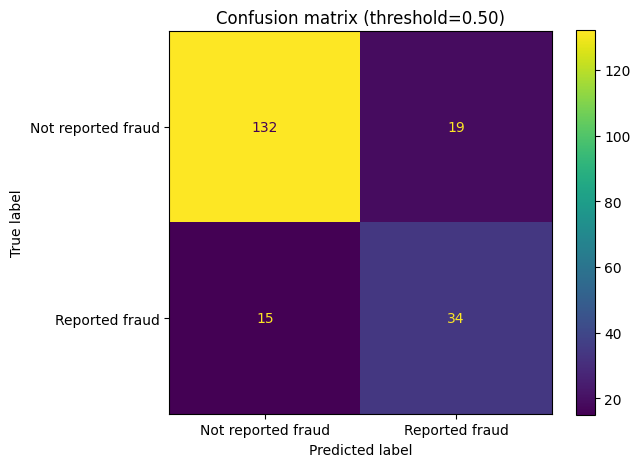

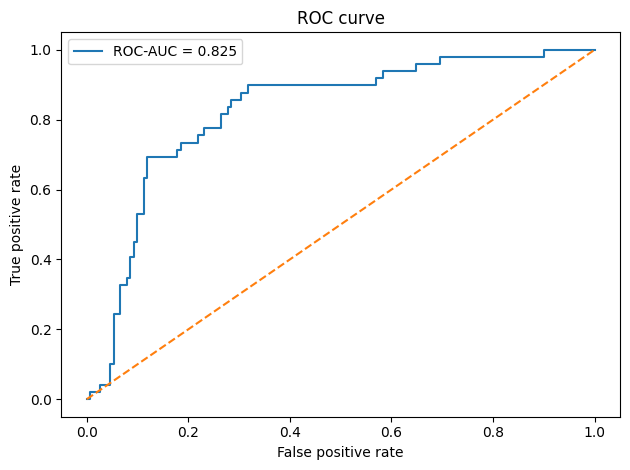

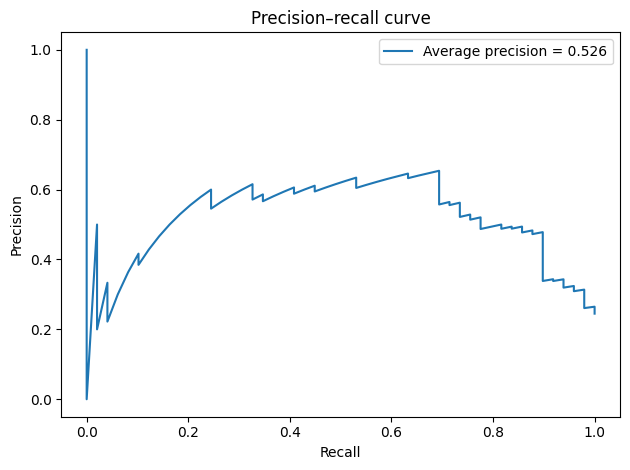

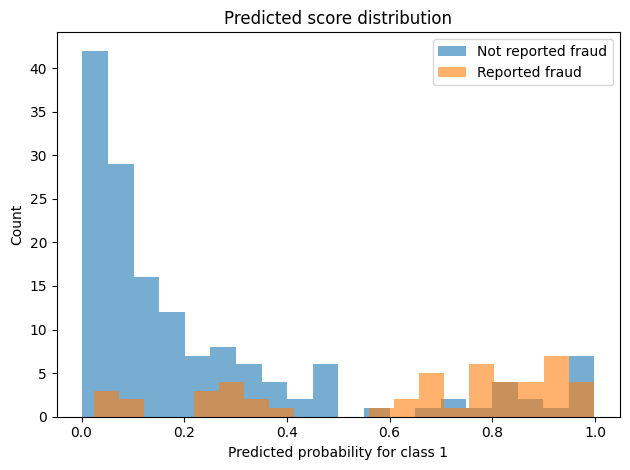

In [6]:
# Use a transparent default threshold for the baseline. Threshold tuning belongs on validation data,
# not the final test set. Do not interpret a chosen threshold as an operational policy.
threshold = 0.50
y_prob = pipeline.predict_proba(X_test)[:, 1]
y_pred = (y_prob >= threshold).astype(int)

metrics = {
    "accuracy": accuracy_score(y_test, y_pred),
    "precision": precision_score(y_test, y_pred, zero_division=0),
    "recall": recall_score(y_test, y_pred, zero_division=0),
    "f1": f1_score(y_test, y_pred, zero_division=0),
    "roc_auc": roc_auc_score(y_test, y_prob),
    "average_precision": average_precision_score(y_test, y_prob),
}
display(pd.DataFrame([metrics]).T.rename(columns={0:"test_value"}))
print(classification_report(y_test, y_pred, target_names=["Not reported fraud", "Reported fraud"], zero_division=0))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, display_labels=["Not reported fraud", "Reported fraud"], values_format="d"
)
plt.title(f"Confusion matrix (threshold={threshold:.2f})")
plt.tight_layout()
plt.show()

fpr, tpr, _ = roc_curve(y_test, y_prob)
plt.plot(fpr, tpr, label=f"ROC-AUC = {metrics['roc_auc']:.3f}")
plt.plot([0, 1], [0, 1], linestyle="--")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.title("ROC curve")
plt.legend()
plt.tight_layout()
plt.show()

precision, recall, _ = precision_recall_curve(y_test, y_prob)
plt.plot(recall, precision, label=f"Average precision = {metrics['average_precision']:.3f}")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision–recall curve")
plt.legend()
plt.tight_layout()
plt.show()

plt.hist(y_prob[y_test.to_numpy() == 0], bins=20, alpha=0.6, label="Not reported fraud")
plt.hist(y_prob[y_test.to_numpy() == 1], bins=20, alpha=0.6, label="Reported fraud")
plt.xlabel("Predicted probability for class 1")
plt.ylabel("Count")
plt.title("Predicted score distribution")
plt.legend()
plt.tight_layout()
plt.show()

## 7. Save artifacts and metadata

Only load joblib files you created or otherwise trust. Joblib uses pickle-based serialization, which can execute code when loading untrusted artifacts. Training and serving should use matching dependency versions.

In [7]:
# Save model, threshold, and metadata required by the Streamlit app.
joblib.dump(pipeline, ARTIFACT_DIR / "insurance_fraud_pipeline.joblib")
joblib.dump(float(threshold), ARTIFACT_DIR / "decision_threshold.joblib")

metadata = {
    "project_name": "Insurance Fraud Detection — Logistic Regression",
    "target_column": TARGET,
    "positive_class": 1,
    "positive_class_label": "Reported fraud",
    "threshold": float(threshold),
    "feature_columns": X.columns.tolist(),
    "numeric_features": numeric_features,
    "categorical_features": categorical_features,
    "identifier_columns_excluded": identifier_candidates,
    "constant_columns_excluded": constant_columns,
    "metrics_test": {k: float(v) for k, v in metrics.items()},
    "random_state": RANDOM_STATE,
    "test_size": 0.20,
    "dataset_source": DATA_URL,
    "dataset_record": DATASET_RECORD,
    "dataset_license_claimed_by_source": "CC BY 4.0; verify current source record before redistribution",
    "dataset_sha256": hashlib.sha256(data_path.read_bytes()).hexdigest(),
    "python_version": sys.version,
    "sklearn_version": sklearn.__version__,
    "numpy_version": np.__version__,
    "scipy_version": scipy.__version__,
    "joblib_version": joblib.__version__,
    "feature_leakage_review_required": True,
    "educational_only": True
}
(ARTIFACT_DIR / "model_metadata.json").write_text(json.dumps(metadata, indent=2))
print("Saved:")
for p in sorted(ARTIFACT_DIR.iterdir()):
    print("-", p, f"({p.stat().st_size:,} bytes)")

Saved:
- artifacts/decision_threshold.joblib (21 bytes)
- artifacts/insurance_fraud_pipeline.joblib (12,378 bytes)
- artifacts/model_metadata.json (2,897 bytes)


## 8. Round-trip artifact test

In [8]:
# Confirm the serialized pipeline reloads and produces the same predictions.
reloaded = joblib.load(ARTIFACT_DIR / "insurance_fraud_pipeline.joblib")
reloaded_probs = reloaded.predict_proba(X_test.iloc[:10])[:, 1]
assert np.allclose(reloaded_probs, y_prob[:10]), "Predictions changed after reload."
assert np.isfinite(reloaded_probs).all()
print("Artifact round-trip test passed.")

Artifact round-trip test passed.


## 9. Export generated artifacts for Streamlit

Run this cell after the model save and round-trip test cells. It verifies all required outputs and downloads a ZIP containing the three files your Streamlit app expects.


In [10]:
from zipfile import ZipFile, ZIP_DEFLATED
from pathlib import Path

# Verify the exact artifacts required by app.py.
required_artifacts = [
    ARTIFACT_DIR / "insurance_fraud_pipeline.joblib",
    ARTIFACT_DIR / "decision_threshold.joblib",
    ARTIFACT_DIR / "model_metadata.json",
]
missing = [str(p) for p in required_artifacts if not p.exists()]
if missing:
    raise FileNotFoundError("Missing artifacts: " + ", ".join(missing) + ". Run the Save artifacts and metadata cell first.")

export_zip = Path("insurance_fraud_artifacts.zip")
with ZipFile(export_zip, "w", ZIP_DEFLATED) as archive:
    for artifact in required_artifacts:
        archive.write(artifact, arcname=f"artifacts/{artifact.name}")

print("Artifacts ready for the insurance Streamlit app:")
for artifact in required_artifacts:
    print(f"- {artifact} ({artifact.stat().st_size:,} bytes)")
print(f"Created: {export_zip.resolve()}")

# Trigger browser download when running in Google Colab.
try:
    from google.colab import files
    files.download(str(export_zip))
except ImportError:
    print("Not running in Colab. Download insurance_fraud_artifacts.zip from the runtime files panel.")


Artifacts ready for the insurance Streamlit app:
- artifacts/insurance_fraud_pipeline.joblib (12,378 bytes)
- artifacts/decision_threshold.joblib (21 bytes)
- artifacts/model_metadata.json (2,897 bytes)
Created: /content/insurance_fraud_artifacts.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 10. Deployment checklist

- [ ] The training pipeline fit successfully.
- [ ] Evaluation metrics and plots reviewed.
- [ ] Artifact round-trip test passed.
- [ ] Final export cell downloaded `insurance_fraud_artifacts.zip`.
- [ ] ZIP extracted so the three files are inside this project's `artifacts/` folder.
- [ ] Streamlit deployment uses this folder's `app.py` and `requirements.txt`.
- [ ] Package versions match the versions stored in `model_metadata.json`.

This is an educational demonstration, not an automated fraud determination system.
